# Forecasting Student Academic Performance Using Machine Learning

**Module:** Machine Learning  
**Supervisor:** Dr. Muhammad Iqbal                 
**Programme:** Higher Diploma in Data Analytics  
**College:** CCT College Dublin  
**Student:** MONICA VALENCIANO BARAJAS  
**Dataset:** UCI Student Performance – Portuguese Language (student-por.csv)

## Research Question

Which academic, demographic and social factors are most useful for predicting students' final academic performance in Portuguese?

## Project Overview

This project uses the UCI Student Performance dataset to investigate which academic, demographic and social factors are useful for predicting students' final grades in Portuguese.

Three regression models will be developed and compared: Linear Regression, Decision Tree Regressor and Random Forest Regressor.

The final grade (G3) will be used as the target variable, while the previous period grades (G1 and G2) will be excluded from the predictors.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Loading

In this section, the dataset will be imported into Python using pandas.

In [3]:
df = pd.read_csv('student-por.csv')

In [4]:
df.head()

,school;sex;age;address;famsize;Pstatus;Medu;Fedu;Mjob;Fjob;reason;guardian;traveltime;studytime;failures;schoolsup;famsup;paid;activities;nursery;higher;internet;romantic;famrel;freetime;goout;Dalc;Walc;health;absences;G1;G2;G3
0,"GP;""F"";18;""U"";""GT3"";""A"";4;4;""at_home"";""teacher..."
1,"GP;""F"";17;""U"";""GT3"";""T"";1;1;""at_home"";""other"";..."
2,"GP;""F"";15;""U"";""LE3"";""T"";1;1;""at_home"";""other"";..."
3,"GP;""F"";15;""U"";""GT3"";""T"";4;2;""health"";""services..."
4,"GP;""F"";16;""U"";""GT3"";""T"";3;3;""other"";""other"";""h..."


In [5]:
df = pd.read_csv('student-por.csv', sep=';')

In [6]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


The dataset is imported using the pandas read_csv() function. The parameter sep=';' is included because the CSV file uses semicolons to separate the columns. This ensures that each variable is correctly recognised as a separate column.

### Dataset Overview

In this section, the dimensions of the dataset are examined to understand how many student records and variables are available for the analysis.

In [7]:
df.shape

(649, 33)

### Dataset Variables

The dataset contains several variables describing students' demographic characteristics, family backgrounds, school-related information and academic performance. The column names are examined to understand the information available for the analysis.

In [9]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='str')

### Data Types

In this section, the data types of each variable are examined to identify numerical and categorical columns and understand how the dataset is structured.

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

### Missing Values Check

A missing values check is performed to identify whether any variables contain incomplete records that could affect the data preparation and machine learning process.

In [12]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

**Missing Values Analysis**

The missing values check shows that all 33 variables contain 0 missing values. Each variable has 649 non-null records. 

### Descriptive Statistics

Descriptive statistics are used to examine the numerical variables in the dataset. This provides an overview of their distributions, central values and variability.

In [14]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


**Descriptive Statistics Analysis**

The descriptive statistics show that the dataset contains 649 students, with an average age of approximately 16.7 years.

The average number of absences is 3.54, while the maximum is 32, indicating variation in student attendance.

The average final grade (G3) is approximately 11.91 out of 20. The mean grades increase slightly across the three academic periods.

These results provide an initial understanding of the dataset and help identify variables that may be relevant to the prediction of final academic performance.

### Categorical Variables Exploration

The categorical variables are examined to identify their unique categories before applying LabelEncoder during the data preparation stage.

In [19]:
df['school'].unique()

<ArrowStringArray>
['GP', 'MS']
Length: 2, dtype: str

In [20]:
df['sex'].unique()

<ArrowStringArray>
['F', 'M']
Length: 2, dtype: str

In [21]:
df['address'].unique()

<ArrowStringArray>
['U', 'R']
Length: 2, dtype: str

In [22]:
df['famsize'].unique()

<ArrowStringArray>
['GT3', 'LE3']
Length: 2, dtype: str

In [23]:
df['Pstatus'].unique()

<ArrowStringArray>
['A', 'T']
Length: 2, dtype: str

In [24]:
df['Mjob'].unique()

<ArrowStringArray>
['at_home', 'health', 'other', 'services', 'teacher']
Length: 5, dtype: str

In [26]:
df['Fjob'].unique()

<ArrowStringArray>
['teacher', 'other', 'services', 'health', 'at_home']
Length: 5, dtype: str

In [27]:
df['reason'].unique()

<ArrowStringArray>
['course', 'other', 'home', 'reputation']
Length: 4, dtype: str

In [29]:
df['guardian'].unique()

<ArrowStringArray>
['mother', 'father', 'other']
Length: 3, dtype: str

In [30]:
df['schoolsup'].unique()

<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str

The remaining categorical variables describe different aspects of students' educational support, family environment and personal circumstances. These include additional school support, family support, paid classes, extracurricular activities, nursery attendance, interest in higher education, internet access and romantic relationships.

These variables provide additional information that may help investigate factors associated with students' final academic performance.

### 8.Target Variable Exploration

The target variable for this project is G3, which represents the students' final grade in Portuguese. This variable will be used to predict students' final academic performance using Machine Learning regression models.

In [32]:
df['G3'].describe()

count    649.000000
mean      11.906009
std        3.230656
min        0.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       19.000000
Name: G3, dtype: float64

The descriptive statistics show that the dataset contains 649 students. The average final grade (G3) is approximately 11.91 out of 20, while the median is 12. The grades range from 0 to 19, with a standard deviation of approximately 3.23. This indicates that students' final academic performance varies across the dataset.

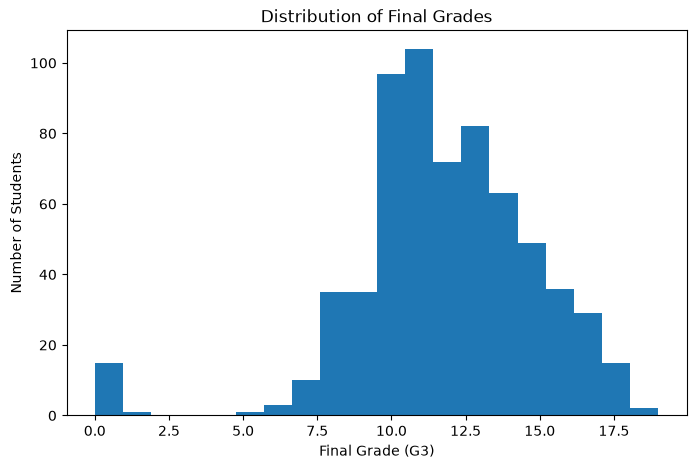

In [34]:
plt.figure(figsize=(8, 5))
plt.hist(df['G3'], bins=20)
plt.xlabel('Final Grade (G3)')
plt.ylabel('Number of Students')
plt.title('Distribution of Final Grades')
plt.show()

The histogram shows the distribution of students' final grades (G3). Most students achieved grades between approximately 10 and 14, with the highest concentration around 10–11. The frequency of students generally decreases towards the higher grades.

A small number of students received a grade of 0. However, the reason for these results cannot be determined from the available data.

Overall, the histogram indicates variation in students' final academic performance, making G3 a suitable numerical target variable for regression analysis.

In [35]:
X = df.drop(['G1', 'G2', 'G3'], axis=1)

In [37]:
y = df['G3']

In [38]:
print(X.shape)
print(y.shape)

(649, 30)
(649,)


The dataset was divided into predictor variables (X) and the target variable (y). The predictor dataset contains 649 records and 30 features, while the target variable contains 649 final grades (G3). The variables G1 and G2 were excluded to avoid using previous academic grades as predictors.

###  Encoding Categorical Variables

In [40]:
from sklearn.preprocessing import LabelEncoder

In [41]:
X.select_dtypes(include='str').columns

Index(['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob',
       'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities',
       'nursery', 'higher', 'internet', 'romantic'],
      dtype='str')

Machine Learning models require numerical input data. However, the dataset contains categorical variables represented as text.
The LabelEncoder method from Scikit-learn will be used to convert these categorical values into numerical labels.
First, the categorical columns were identified to distinguish them from the numerical variables. Only the categorical variables will require encoding.
This preparation step will allow the dataset to be used by the selected Machine Learning regression models.

### Train-Test Split

In [42]:
from sklearn.model_selection import train_test_split

In [88]:
### 0.05
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.05, random_state=42)

In [89]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(616, 30)
(33, 30)
(616,)
(33,)


The dataset was divided into training and testing sets using the train_test_split method from Scikit-learn.
The first split uses 95% of the data for training and 5% for testing. The training set contains 616 students, while the testing set contains 33 students.
The random_state=42 parameter ensures that the same data split can be reproduced when the code is executed again.
The training data will be used to build the Machine Learning models, while the testing data will be used to evaluate their predictive performance.

###  Encoding Categorical Variables

Categorical variables are represented as text and need to be converted into numerical values before training the Machine Learning models.
The LabelEncoder method from Scikit-learn is used to transform categorical values into numerical labels.
The encoder is fitted using the training data and then applied to the testing data using the same encoding. This prevents information from the testing set from being used during the fitting process.

In [90]:
categorical_columns = X.select_dtypes(include='str').columns

In [91]:
le = LabelEncoder()

X_train['school'] = le.fit_transform(X_train['school'])
X_test['school'] = le.transform(X_test['school'])

In [92]:
print(X_train['school'].unique())

[1 0]


In [93]:
le = LabelEncoder()

X_train['sex'] = le.fit_transform(X_train['sex'])
X_test['sex'] = le.transform(X_test['sex'])

In [94]:
print(X_train['sex'].unique())

[0 1]


In [95]:
le = LabelEncoder()

X_train['address'] = le.fit_transform(X_train['address'])
X_test['address'] = le.transform(X_test['address'])

In [96]:
print(X_train['address'].unique())

[0 1]


In [97]:
le = LabelEncoder()

X_train['famsize'] = le.fit_transform(X_train['famsize'])
X_test['famsize'] = le.transform(X_test['famsize'])

In [98]:
print(X_train['famsize'].unique())

[0 1]


In [99]:
le = LabelEncoder()

X_train['Pstatus'] = le.fit_transform(X_train['Pstatus'])
X_test['Pstatus'] = le.transform(X_test['Pstatus'])

In [100]:
print(X_train['Pstatus'].unique())

[1 0]


In [101]:
le = LabelEncoder()

X_train['Mjob'] = le.fit_transform(X_train['Mjob'])
X_test['Mjob'] = le.transform(X_test['Mjob'])

In [102]:
print(X_train['Mjob'].unique())

[0 2 3 4 1]


In [103]:
le = LabelEncoder()

X_train['Fjob'] = le.fit_transform(X_train['Fjob'])
X_test['Fjob'] = le.transform(X_test['Fjob'])

In [104]:
print(X_train['Fjob'].unique())

[2 3 4 0 1]


In [105]:
le = LabelEncoder()

X_train['reason'] = le.fit_transform(X_train['reason'])
X_test['reason'] = le.transform(X_test['reason'])

In [106]:
print(X_train['reason'].unique())

[0 1 3 2]


In [107]:
le = LabelEncoder()

X_train['guardian'] = le.fit_transform(X_train['guardian'])
X_test['guardian'] = le.transform(X_test['guardian'])

In [108]:
print(X_train['guardian'].unique())

[0 1 2]


In [109]:
le = LabelEncoder()

X_train['schoolsup'] = le.fit_transform(X_train['schoolsup'])
X_test['schoolsup'] = le.transform(X_test['schoolsup'])

In [110]:
print(X_train['schoolsup'].unique())

[1 0]


In [111]:
le = LabelEncoder()

X_train['famsup'] = le.fit_transform(X_train['famsup'])
X_test['famsup'] = le.transform(X_test['famsup'])

In [112]:
print(X_train['famsup'].unique())

[1 0]


In [113]:
le = LabelEncoder()

X_train['paid'] = le.fit_transform(X_train['paid'])
X_test['paid'] = le.transform(X_test['paid'])

In [114]:
print(X_train['paid'].unique())

[0 1]


In [115]:
le = LabelEncoder()

X_train['activities'] = le.fit_transform(X_train['activities'])
X_test['activities'] = le.transform(X_test['activities'])

In [116]:
print(X_train['activities'].unique())

[0 1]


In [117]:
le = LabelEncoder()

X_train['nursery'] = le.fit_transform(X_train['nursery'])
X_test['nursery'] = le.transform(X_test['nursery'])

In [118]:
print(X_train['nursery'].unique())

[1 0]


In [119]:
le = LabelEncoder()

X_train['higher'] = le.fit_transform(X_train['higher'])
X_test['higher'] = le.transform(X_test['higher'])

In [120]:
print(X_train['higher'].unique())

[1 0]


In [121]:
le = LabelEncoder()

X_train['internet'] = le.fit_transform(X_train['internet'])
X_test['internet'] = le.transform(X_test['internet'])

In [122]:
print(X_train['internet'].unique())

[0 1]


In [123]:
le = LabelEncoder()

X_train['romantic'] = le.fit_transform(X_train['romantic'])
X_test['romantic'] = le.transform(X_test['romantic'])

In [124]:
print(X_train['romantic'].unique())

[0 1]


Categorical variables contain text values and need to be converted into numerical values before they can be used by Machine Learning models.
The `LabelEncoder` method was used to encode the 17 categorical variables. The encoder was fitted on the training data and then applied to the testing data to maintain consistent numerical labels.
This process prepares the categorical features for the Machine Learning models.

In [125]:
print(X_train.dtypes)

school        int64
sex           int64
age           int64
address       int64
famsize       int64
Pstatus       int64
Medu          int64
Fedu          int64
Mjob          int64
Fjob          int64
reason        int64
guardian      int64
traveltime    int64
studytime     int64
failures      int64
schoolsup     int64
famsup        int64
paid          int64
activities    int64
nursery       int64
higher        int64
internet      int64
romantic      int64
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
dtype: object


The data types were checked after encoding to confirm that all 30 predictor variables were numerical. No categorical text columns remained in the training dataset.

In [127]:
### 0.15
X_train_15, X_test_15, y_train_15, y_test_15 = train_test_split(X, y, test_size=0.15, random_state=42)

In [128]:
print(X_train_15.shape)
print(X_test_15.shape)
print(y_train_15.shape)
print(y_test_15.shape)

(551, 30)
(98, 30)
(551,)
(98,)


In [129]:
le = LabelEncoder()

X_train_15['school'] = le.fit_transform(X_train_15['school'])
X_test_15['school'] = le.transform(X_test_15['school'])

In [130]:
print(X_train_15['school'].unique())

[0 1]


In [131]:
le = LabelEncoder()

X_train_15['sex'] = le.fit_transform(X_train_15['sex'])
X_test_15['sex'] = le.transform(X_test_15['sex'])

In [132]:
print(X_train_15['sex'].unique())

[1 0]


In [133]:
le = LabelEncoder()

X_train_15['address'] = le.fit_transform(X_train_15['address'])
X_test_15['address'] = le.transform(X_test_15['address'])

In [134]:
print(X_train_15['address'].unique())

[0 1]


In [135]:
le = LabelEncoder()

X_train_15['famsize'] = le.fit_transform(X_train_15['famsize'])
X_test_15['famsize'] = le.transform(X_test_15['famsize'])

In [136]:
print(X_train_15['famsize'].unique())

[1 0]


In [137]:
le = LabelEncoder()

X_train_15['Pstatus'] = le.fit_transform(X_train_15['Pstatus'])
X_test_15['Pstatus'] = le.transform(X_test_15['Pstatus'])

In [138]:
print(X_train_15['Pstatus'].unique())

[0 1]


In [139]:
le = LabelEncoder()

X_train_15['Mjob'] = le.fit_transform(X_train_15['Mjob'])
X_test_15['Mjob'] = le.transform(X_test_15['Mjob'])

In [140]:
print(X_train_15['Mjob'].unique())

[4 2 3 0 1]


In [141]:
le = LabelEncoder()

X_train_15['Fjob'] = le.fit_transform(X_train_15['Fjob'])
X_test_15['Fjob'] = le.transform(X_test_15['Fjob'])

In [142]:
print(X_train_15['Fjob'].unique())

[2 1 3 0 4]


In [143]:
le = LabelEncoder()

X_train_15['reason'] = le.fit_transform(X_train_15['reason'])
X_test_15['reason'] = le.transform(X_test_15['reason'])

In [144]:
print(X_train_15['reason'].unique())

[0 2 1 3]


In [145]:
le = LabelEncoder()

X_train_15['guardian'] = le.fit_transform(X_train_15['guardian'])
X_test_15['guardian'] = le.transform(X_test_15['guardian'])

In [146]:
print(X_train_15['guardian'].unique())

[1 2 0]


In [147]:
le = LabelEncoder()

X_train_15['schoolsup'] = le.fit_transform(X_train_15['schoolsup'])
X_test_15['schoolsup'] = le.transform(X_test_15['schoolsup'])

In [148]:
print(X_train_15['schoolsup'].unique())

[0 1]


In [149]:
le = LabelEncoder()

X_train_15['famsup'] = le.fit_transform(X_train_15['famsup'])
X_test_15['famsup'] = le.transform(X_test_15['famsup'])

In [150]:
print(X_train_15['famsup'].unique())

[1 0]


In [151]:
le = LabelEncoder()

X_train_15['paid'] = le.fit_transform(X_train_15['paid'])
X_test_15['paid'] = le.transform(X_test_15['paid'])

In [154]:
print(X_train_15['paid'].unique())

[0 1]


In [156]:
le = LabelEncoder()

X_train_15['activities'] = le.fit_transform(X_train_15['activities'])
X_test_15['activities'] = le.transform(X_test_15['activities'])

In [157]:
print(X_train_15['activities'].unique())

[0 1]


In [158]:
le = LabelEncoder()

X_train_15['nursery'] = le.fit_transform(X_train_15['nursery'])
X_test_15['nursery'] = le.transform(X_test_15['nursery'])

In [159]:
print(X_train_15['nursery'].unique())

[1 0]


In [160]:
le = LabelEncoder()

X_train_15['higher'] = le.fit_transform(X_train_15['higher'])
X_test_15['higher'] = le.transform(X_test_15['higher'])

In [161]:
print(X_train_15['higher'].unique())

[1 0]


In [162]:
le = LabelEncoder()

X_train_15['internet'] = le.fit_transform(X_train_15['internet'])
X_test_15['internet'] = le.transform(X_test_15['internet'])

In [163]:
print(X_train_15['internet'].unique())

[1 0]


In [164]:
le = LabelEncoder()

X_train_15['romantic'] = le.fit_transform(X_train_15['romantic'])
X_test_15['romantic'] = le.transform(X_test_15['romantic'])

In [165]:
print(X_train_15['romantic'].unique())

[0 1]


In [166]:
print(X_train_15.dtypes)

school        int64
sex           int64
age           int64
address       int64
famsize       int64
Pstatus       int64
Medu          int64
Fedu          int64
Mjob          int64
Fjob          int64
reason        int64
guardian      int64
traveltime    int64
studytime     int64
failures      int64
schoolsup     int64
famsup        int64
paid          int64
activities    int64
nursery       int64
higher        int64
internet      int64
romantic      int64
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
dtype: object


In [167]:
print(X_test_15.dtypes)

school        int64
sex           int64
age           int64
address       int64
famsize       int64
Pstatus       int64
Medu          int64
Fedu          int64
Mjob          int64
Fjob          int64
reason        int64
guardian      int64
traveltime    int64
studytime     int64
failures      int64
schoolsup     int64
famsup        int64
paid          int64
activities    int64
nursery       int64
higher        int64
internet      int64
romantic      int64
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
dtype: object


The dataset was divided into training and testing sets using three different proportions: 95/5, 85/15 and 75/25.
The training data will be used to build the Machine Learning models, while the testing data will be used to evaluate their performance on unseen data.
Comparing these three splits will help determine how the amount of training data affects model performance.

In [169]:
X_train_25, X_test_25, y_train_25, y_test_25 = train_test_split(X, y, test_size=0.25, random_state=42)

In [170]:
print(X_train_25.shape)
print(X_test_25.shape)
print(y_train_25.shape)
print(y_test_25.shape)

(486, 30)
(163, 30)
(486,)
(163,)


In [172]:
le = LabelEncoder()
X_train_25['school'] = le.fit_transform(X_train_25['school'])
X_test_25['school'] = le.transform(X_test_25['school'])

In [189]:
print(X_train_25['school'].unique())

[0 1]


In [191]:
le = LabelEncoder()
X_train_25['address'] = le.fit_transform(X_train_25['address'])
X_test_25['address'] = le.transform(X_test_25['address'])

In [192]:
print(X_train_25['address'].unique())

[1 0]


In [193]:
le = LabelEncoder()
X_train_25['famsize'] = le.fit_transform(X_train_25['famsize'])
X_test_25['famsize'] = le.transform(X_test_25['famsize'])

In [194]:
print(X_train_25['famsize'].unique())

[1 0]


In [176]:
le = LabelEncoder()
X_train_25['Pstatus'] = le.fit_transform(X_train_25['Pstatus'])
X_test_25['Pstatus'] = le.transform(X_test_25['Pstatus'])

In [195]:
print(X_train_25['Pstatus'].unique())


[1 0]


In [177]:
le = LabelEncoder()
X_train_25['Mjob'] = le.fit_transform(X_train_25['Mjob'])
X_test_25['Mjob'] = le.transform(X_test_25['Mjob'])

In [196]:
print(X_train_25['Mjob'].unique())

[4 3 2 0 1]


In [178]:
le = LabelEncoder()
X_train_25['Fjob'] = le.fit_transform(X_train_25['Fjob'])
X_test_25['Fjob'] = le.transform(X_test_25['Fjob'])

In [197]:
print(X_train_25['Fjob'].unique())

[4 3 2 0 1]


In [179]:
le = LabelEncoder()
X_train_25['reason'] = le.fit_transform(X_train_25['reason'])
X_test_25['reason'] = le.transform(X_test_25['reason'])

In [198]:
print(X_train_25['reason'].unique())


[3 0 2 1]


In [180]:
le = LabelEncoder()
X_train_25['guardian'] = le.fit_transform(X_train_25['guardian'])
X_test_25['guardian'] = le.transform(X_test_25['guardian'])

In [199]:
print(X_train_25['guardian'].unique())


[1 0 2]


In [181]:
le = LabelEncoder()
X_train_25['schoolsup'] = le.fit_transform(X_train_25['schoolsup'])
X_test_25['schoolsup'] = le.transform(X_test_25['schoolsup'])

In [200]:
print(X_train_25['schoolsup'].unique())


[0 1]


In [182]:
le = LabelEncoder()
X_train_25['famsup'] = le.fit_transform(X_train_25['famsup'])
X_test_25['famsup'] = le.transform(X_test_25['famsup'])

In [201]:
print(X_train_25['famsup'].unique())


[1 0]


In [202]:
le = LabelEncoder()
X_train_25['paid'] = le.fit_transform(X_train_25['paid'])
X_test_25['paid'] = le.transform(X_test_25['paid'])

In [203]:
print(X_train_25['paid'].unique())

[0 1]


In [184]:
le = LabelEncoder()
X_train_25['activities'] = le.fit_transform(X_train_25['activities'])
X_test_25['activities'] = le.transform(X_test_25['activities'])

In [204]:
print(X_train_25['activities'].unique())


[0 1]


In [185]:
le = LabelEncoder()
X_train_25['nursery'] = le.fit_transform(X_train_25['nursery'])
X_test_25['nursery'] = le.transform(X_test_25['nursery'])

In [205]:
print(X_train_25['nursery'].unique())


[1 0]


In [186]:
le = LabelEncoder()
X_train_25['higher'] = le.fit_transform(X_train_25['higher'])
X_test_25['higher'] = le.transform(X_test_25['higher'])

In [206]:
print(X_train_25['higher'].unique())


[1 0]


In [187]:
le = LabelEncoder()
X_train_25['internet'] = le.fit_transform(X_train_25['internet'])
X_test_25['internet'] = le.transform(X_test_25['internet'])

In [207]:
print(X_train_25['internet'].unique())


[1 0]


In [188]:
le = LabelEncoder()
X_train_25['romantic'] = le.fit_transform(X_train_25['romantic'])
X_test_25['romantic'] = le.transform(X_test_25['romantic'])

In [208]:
print(X_train_25['romantic'].unique())

[0 1]


In [209]:
print(X_train_25.dtypes)
print(X_test_25.dtypes)

school        int64
sex           int64
age           int64
address       int64
famsize       int64
Pstatus       int64
Medu          int64
Fedu          int64
Mjob          int64
Fjob          int64
reason        int64
guardian      int64
traveltime    int64
studytime     int64
failures      int64
schoolsup     int64
famsup        int64
paid          int64
activities    int64
nursery       int64
higher        int64
internet      int64
romantic      int64
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
dtype: object
school        int64
sex           int64
age           int64
address       int64
famsize       int64
Pstatus       int64
Medu          int64
Fedu          int64
Mjob          int64
Fjob          int64
reason        int64
guardian      int64
traveltime    int64
studytime     int64
failures      int64
schoolsup     int64
famsup        int64
paid          int64
activities    int64
nurser

### Conclusion 

Three different train-test split scenarios were created to evaluate the Machine Learning models using different amounts of training and testing data.
The first scenario used 95% of the data for training and 5% for testing (616 training records and 33 testing records). The second scenario used 85% for training and 15% for testing (551 training records and 98 testing records). The third scenario used 75% for training and 25% for testing (486 training records and 163 testing records).

All three scenarios contain 649 student records in total. The categorical variables were encoded into numerical values, and all predictor columns were confirmed to have the "int64" data type.
Using three different splits will allow us to compare how the amount of training and testing data affects the predictive performance of the Machine Learning models.

### Training the Machine Learning Models

### Linear Regression

In [225]:
from sklearn.linear_model import LinearRegression

In [226]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](30,)","[-1.56,-0.56, 0.19,...,-0.07,-0.2 ,-0.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](30,)","['school','sex','age',...,'Walc','health','absences']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.264
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,30
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(30)


In [227]:
y_pred = lr_model.predict(X_test)

In [228]:
print("Actual Values:")
print(y_test.values)

print("Predicted Values:")
print(y_pred)

Actual Values:
[19 12 18 11 11 17 18  8 10 11 18 11 12  9 12 14 13  8 15 14 15 13 13 13
 16 13  8 12 10 15 16 12  9]
Predicted Values:
[12.36227007 12.686709   13.36818259 12.02066383 10.1987417  11.9206807
 13.20461454  6.62597374 13.17278491 12.66532263 11.86448327 11.88037596
 13.35951057 11.87009605 10.07257322 13.98133945 13.47260319  9.93517141
 13.85554342 14.16975028 12.6306879  12.53402358 14.40671734 13.04504881
 11.47055054 13.19252426  9.57677032 14.57250193 12.00392659 13.42291305
 11.9467847  13.24119764  7.7319077 ]


In [229]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [230]:
print("R2 Score:", r2_score(y_test, y_pred))

print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))

print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

R2 Score: 0.17215230330456044
Mean Absolute Error: 2.123648623613544
Mean Squared Error: 7.644477904471388


The Linear Regression model achieved an R² score of 0.1722, a Mean Absolute Error (MAE) of 2.1236 and a Mean Squared Error (MSE) of 7.6445.
The model explains approximately 17.22% of the variation in students' final grades. Its predictions differ from the actual grades by approximately 2.12 points on average.
These results indicate limited predictive performance for this train-test split. However, further evaluation using different train-test splits and other Machine Learning models is required before drawing final conclusions.

In [231]:
lr_model_15 = LinearRegression()

lr_model_15.fit(X_train_15, y_train_15)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](30,)","[-1.72,-0.39, 0.13,...,-0.03,-0.23,-0.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](30,)","['school','sex','age',...,'Walc','health','absences']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9.468
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,30
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(30)


In [232]:
y_pred_15 = lr_model_15.predict(X_test_15)

In [233]:
print("Actual Values:")
print(y_test_15.values)

print("Predicted Values:")
print(y_pred_15)

Actual Values:
[19 12 18 11 11 17 18  8 10 11 18 11 12  9 12 14 13  8 15 14 15 13 13 13
 16 13  8 12 10 15 16 12  9  8 18 16 14 15 14 11 13 10  8 11 14 12 18 12
 14 12 10 11 14 11 11 18 10 11 11 10 10 11 16 14 17 15 11 10  0 10 16 15
 12 16 13 12 13 15 13 14 11 12 17  8 12 17 11  9 15 13 14  9 11 18  9 15
 16 10]
Predicted Values:
[12.2305047  12.600653   13.04719385 12.13885864 10.08668742 11.73406596
 13.17782656  6.54264478 13.20539498 12.51643597 11.47495733 12.14079923
 13.63926008 11.9414194   9.5245326  14.23289017 13.44676439  9.72571461
 13.60027144 14.44516735 12.8793139  12.39689999 14.43511426 13.09692109
 11.22938517 12.99918657  9.99938596 14.32390979 11.65459982 13.48389612
 11.73985032 13.19411155  7.65391213  5.74141695  9.80669988 13.38099509
 12.92672918 14.31703231 12.83451117 11.95776321 12.88162796 13.69729173
 12.22045075 13.78869226 11.88367054 11.24440748 12.18655605 13.08686881
 13.58806216 11.47256654 11.03499768 13.66811479 10.1049768   9.10122608
 12.349654

In [234]:
print("R2 Score:", r2_score(y_test_15, y_pred_15))

print("Mean Absolute Error:", mean_absolute_error(y_test_15, y_pred_15))

print("Mean Squared Error:", mean_squared_error(y_test_15, y_pred_15))

R2 Score: 0.21674910833575012
Mean Absolute Error: 2.1194482910895434
Mean Squared Error: 7.506371857524908


The Linear Regression model achieved an R² score of 0.2167, a Mean Absolute Error (MAE) of 2.1194 and a Mean Squared Error (MSE) of 7.5064.

The model explains approximately 21.67% of the variation in students' final grades. Compared with the 95/5 scenario, the R² score increased while both MAE and MSE decreased slightly.
These results indicate a modest improvement in predictive performance. However, the model still has limited explanatory power.

In [235]:
lr_model_25 = LinearRegression()

lr_model_25.fit(X_train_25, y_train_25)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](30,)","[-1.56,-0.25, 0.11,...,-0.01,-0.21,-0.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](30,)","['school','sex','age',...,'Walc','health','absences']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9.764
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,30
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(30)


In [236]:
y_pred_25 = lr_model_25.predict(X_test_25)

In [237]:
print("Actual Values:")
print(y_test_25.values)

print("Predicted Values:")
print(y_pred_25)

Actual Values:
[19 12 18 11 11 17 18  8 10 11 18 11 12  9 12 14 13  8 15 14 15 13 13 13
 16 13  8 12 10 15 16 12  9  8 18 16 14 15 14 11 13 10  8 11 14 12 18 12
 14 12 10 11 14 11 11 18 10 11 11 10 10 11 16 14 17 15 11 10  0 10 16 15
 12 16 13 12 13 15 13 14 11 12 17  8 12 17 11  9 15 13 14  9 11 18  9 15
 16 10 12 10 12 11 10 11 13 10 11 11 10 13 13 11 11 10  8 11 11 16 16 10
 14  0 15 14 12  7 17 11 12 10 18 12 12 13 10 11  9 10  0 12 11 12 12 11
 11  8 13 13 16 12 16 10  6 15 13  9 12 17 11 13 13 17 10]
Predicted Values:
[12.21261226 12.71538095 12.92447801 12.51872316 10.25526021 11.95925916
 13.28265996  6.41104819 13.21363072 12.397332   11.79552683 12.36632274
 14.08970689 12.10096416  9.62037648 14.2728175  13.27632374  9.93562305
 13.75927326 14.49177427 12.96725989 12.3321246  14.14553231 13.20603998
 11.55446809 12.91520475  9.81364141 14.39119139 11.79846477 13.64659956
 12.11255201 13.6604493   7.54629486  5.3072492   9.82503776 13.32911112
 13.05449138 14.27550413 12.8853

In [238]:
print("R2 Score:", r2_score(y_test_25, y_pred_25))

print("Mean Absolute Error:", mean_absolute_error(y_test_25, y_pred_25))

print("Mean Squared Error:", mean_squared_error(y_test_25, y_pred_25))

R2 Score: 0.21602953537036473
Mean Absolute Error: 2.101558758580398
Mean Squared Error: 7.902908558195058


The 85/15 scenario achieved the highest R² score (0.2167) and the lowest MSE (7.5064). The 75/25 scenario achieved the lowest MAE (2.1016).

Overall, the results are relatively similar across the three scenarios. The 85/15 split showed the best overall balance between explanatory power and prediction error, although the differences were small.
Linear Regression showed limited predictive performance in all three scenarios. Therefore, other Machine Learning models will be evaluated to determine whether they can provide more accurate predictions of students' final grades.

### Decision Tree Regressor

In [240]:
from sklearn.tree import DecisionTreeRegressor

In [241]:
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [242]:
y_pred_dt = dt_model.predict(X_test)

In [243]:
print("Actual Values:")
print(y_test.values)

print("Predicted Values:")
print(y_pred_dt)

Actual Values:
[19 12 18 11 11 17 18  8 10 11 18 11 12  9 12 14 13  8 15 14 15 13 13 13
 16 13  8 12 10 15 16 12  9]
Predicted Values:
[18. 14. 14. 15. 12. 12. 12.  6. 14. 10. 18. 13. 17. 12. 11. 18. 10.  9.
 12. 15. 12. 14. 14. 15. 10. 14. 10. 13. 11.  8. 14. 15.  8.]


In [244]:
print("R2 Score:", r2_score(y_test, y_pred_dt))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred_dt))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred_dt))

R2 Score: -0.03699284009546533
Mean Absolute Error: 2.5454545454545454
Mean Squared Error: 9.575757575757576


The Decision Tree Regressor achieved an R² score of -0.0370, a Mean Absolute Error (MAE) of 2.5455 and a Mean Squared Error (MSE) of 9.5758.
The negative R² score indicates that the model performed worse than predicting the average final grade for all students in the test set.
Compared with Linear Regression, Decision Tree produced a lower R² score and higher prediction errors in this scenario.

In [246]:
dt_model_15 = DecisionTreeRegressor(random_state=42)
dt_model_15.fit(X_train_15, y_train_15)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [247]:
y_pred_dt_15 = dt_model_15.predict(X_test_15)

In [248]:
print("Actual Values:")
print(y_test_15.values)

print("Predicted Values:")
print(y_pred_dt_15)

Actual Values:
[19 12 18 11 11 17 18  8 10 11 18 11 12  9 12 14 13  8 15 14 15 13 13 13
 16 13  8 12 10 15 16 12  9  8 18 16 14 15 14 11 13 10  8 11 14 12 18 12
 14 12 10 11 14 11 11 18 10 11 11 10 10 11 16 14 17 15 11 10  0 10 16 15
 12 16 13 12 13 15 13 14 11 12 17  8 12 17 11  9 15 13 14  9 11 18  9 15
 16 10]
Predicted Values:
[12. 13. 12. 13. 11. 12. 12.  6. 19. 12.  0. 13. 16. 11.  9. 17. 13. 12.
 15. 15. 13. 12. 16. 11.  9. 17. 10. 12. 18. 11. 12. 15.  7.  9. 18. 15.
 17. 18. 17.  7. 13. 13. 15. 15. 15. 11. 10. 13.  8. 16.  9. 13. 10.  8.
 17. 16. 13.  9. 13.  9. 11.  8. 15. 15. 13. 15. 12.  7. 10. 14. 14. 15.
 11. 10. 12. 13. 15. 16. 10. 14. 10. 11. 16. 11. 11. 17. 14. 16. 14. 16.
 17.  5. 13. 11. 11. 15. 10.  9.]


In [249]:
print("R2 Score:", r2_score(y_test_15, y_pred_dt_15))
print("Mean Absolute Error:", mean_absolute_error(y_test_15, y_pred_dt_15))
print("Mean Squared Error:", mean_squared_error(y_test_15, y_pred_dt_15))

R2 Score: -0.653545702458687
Mean Absolute Error: 2.9081632653061225
Mean Squared Error: 15.846938775510203


The Decision Tree Regressor achieved an R² score of -0.6535, a Mean Absolute Error (MAE) of 2.9082 and a Mean Squared Error (MSE) of 15.8469.
The negative R² score indicates that the model performed worse than predicting the average final grade for all students in the test set.
Compared with the 95/5 scenario, the model produced a lower R² score and higher prediction errors. This indicates a decrease in predictive performance for this split.
The results suggest that the Decision Tree model may be sensitive to the train-test split. The final 75/25 scenario will provide further evidence of its performance.

In [250]:
dt_model_25 = DecisionTreeRegressor(random_state=42)
dt_model_25.fit(X_train_25, y_train_25)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [251]:
y_pred_dt_25 = dt_model_25.predict(X_test_25)

In [252]:
print("Actual Values:")
print(y_test_25.values)

print("Predicted Values:")
print(y_pred_dt_25)

Actual Values:
[19 12 18 11 11 17 18  8 10 11 18 11 12  9 12 14 13  8 15 14 15 13 13 13
 16 13  8 12 10 15 16 12  9  8 18 16 14 15 14 11 13 10  8 11 14 12 18 12
 14 12 10 11 14 11 11 18 10 11 11 10 10 11 16 14 17 15 11 10  0 10 16 15
 12 16 13 12 13 15 13 14 11 12 17  8 12 17 11  9 15 13 14  9 11 18  9 15
 16 10 12 10 12 11 10 11 13 10 11 11 10 13 13 11 11 10  8 11 11 16 16 10
 14  0 15 14 12  7 17 11 12 10 18 12 12 13 10 11  9 10  0 12 11 12 12 11
 11  8 13 13 16 12 16 10  6 15 13  9 12 17 11 13 13 17 10]
Predicted Values:
[16. 12. 15.  8. 12. 12. 17.  6. 11. 15. 11. 11. 17. 14. 13. 11. 11.  8.
 12. 14. 11.  8. 13. 11. 14. 14. 10. 12. 15. 13. 10. 15.  7.  0. 11. 11.
 12. 16. 14. 10. 10. 15. 15. 10. 15. 11. 15. 15.  8. 12.  9. 14.  9. 14.
 11. 11. 11. 13. 10.  7. 10. 17. 15. 16. 10. 17. 12.  8. 10. 15. 15. 15.
  8. 12. 13. 13. 14. 16. 13. 14.  9.  9. 14. 10. 11. 13. 15. 10. 11. 15.
 14.  5. 11. 10. 14. 14.  8. 14. 10. 17. 11. 15. 12.  8. 11. 10. 16. 15.
 13. 12. 15. 14. 10. 13.  7. 17.

In [253]:
print("R2 Score:", r2_score(y_test_25, y_pred_dt_25))
print("Mean Absolute Error:", mean_absolute_error(y_test_25, y_pred_dt_25))
print("Mean Squared Error:", mean_squared_error(y_test_25, y_pred_dt_25))

R2 Score: -0.4922638071626988
Mean Absolute Error: 2.9079754601226995
Mean Squared Error: 15.042944785276074


The Decision Tree Regressor achieved its best performance with the 95/5 split, obtaining an R² score of -0.0370, an MAE of 2.5455 and an MSE of 9.5758.
The 85/15 scenario produced the weakest results, while the 75/25 scenario showed a small improvement compared with the 85/15 split.
All three scenarios produced negative R² scores, indicating that the model performed worse than using the average final grade as a prediction.
Compared with Linear Regression, Decision Tree showed weaker predictive performance across all three train-test splits. This suggests that the Decision Tree model, with its current default settings, does not capture the patterns in this dataset as effectively as Linear Regression.

### Random Forest Regressor

In [254]:
from sklearn.ensemble import RandomForestRegressor

In [255]:
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [256]:
y_pred_rf = rf_model.predict(X_test)

In [257]:
print("Actual Values:")
print(y_test.values)

print("Predicted Values:")
print(y_pred_rf)

Actual Values:
[19 12 18 11 11 17 18  8 10 11 18 11 12  9 12 14 13  8 15 14 15 13 13 13
 16 13  8 12 10 15 16 12  9]
Predicted Values:
[11.07 12.95 12.15 11.46 11.88 11.38 14.4   8.05 12.83 12.92 11.97 11.76
 14.05 11.5  11.34 13.16 13.24 11.19 13.03 14.44 12.81 12.31 13.47 12.35
 11.58 13.32  9.73 13.87 13.38 12.92 12.86 13.65  9.84]


In [258]:
print("R2 Score:", r2_score(y_test, y_pred_rf))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred_rf))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred_rf))

R2 Score: 0.08389821002386655
Mean Absolute Error: 2.187878787878788
Mean Squared Error: 8.459430303030302


The Random Forest Regressor achieved an R² score of 0.0839, a Mean Absolute Error (MAE) of 2.1879 and a Mean Squared Error (MSE) of 8.4594.
The model explains approximately 8.39% of the variation in students' final grades. Its predictions differ from the actual grades by approximately 2.19 points on average.
Compared with Decision Tree, Random Forest achieved better predictive performance. However, Linear Regression produced the best results in this scenario.

In [260]:
rf_model_15 = RandomForestRegressor(random_state=42)
rf_model_15.fit(X_train_15, y_train_15)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [261]:
y_pred_rf_15 = rf_model_15.predict(X_test_15)

In [262]:
print("Actual Values:")
print(y_test_15.values)

print("Predicted Values:")
print(y_pred_rf_15)

Actual Values:
[19 12 18 11 11 17 18  8 10 11 18 11 12  9 12 14 13  8 15 14 15 13 13 13
 16 13  8 12 10 15 16 12  9  8 18 16 14 15 14 11 13 10  8 11 14 12 18 12
 14 12 10 11 14 11 11 18 10 11 11 10 10 11 16 14 17 15 11 10  0 10 16 15
 12 16 13 12 13 15 13 14 11 12 17  8 12 17 11  9 15 13 14  9 11 18  9 15
 16 10]
Predicted Values:
[ 9.98 13.03 11.13 12.41 11.82 10.46 14.46  8.42 12.68 12.72 10.29 12.49
 14.78 11.12 10.94 13.51 12.76 11.07 13.53 14.32 12.34 11.64 13.97 12.36
 11.41 13.02  9.56 13.64 12.84 13.06 12.2  13.88  9.36  7.51 11.23 14.32
 14.23 14.46 13.81  9.45 12.15 13.86 13.19 14.48 13.07 11.15 12.31 14.07
 14.24 12.06  8.94 13.6  10.61 10.37 12.85 13.85 11.7  11.39  9.87  8.62
  7.41 13.01 14.06 14.12 13.84 14.35  6.75  8.67  7.21  9.7  13.91 13.69
 11.88 11.32 11.96 11.38 13.75 14.55 12.75 11.05  9.31 10.95 13.89 10.46
 12.1  13.49 13.71 13.55 12.41 12.5  14.59  7.57 12.1  14.34  8.37 14.77
  9.02 12.14]


In [263]:
print("R2 Score:", r2_score(y_test_15, y_pred_rf_15))
print("Mean Absolute Error:", mean_absolute_error(y_test_15, y_pred_rf_15))
print("Mean Squared Error:", mean_squared_error(y_test_15, y_pred_rf_15))

R2 Score: 0.13096090220662515
Mean Absolute Error: 2.1312244897959185
Mean Squared Error: 8.328532653061226


The Random Forest Regressor achieved an R² score of 0.1310, a Mean Absolute Error (MAE) of 2.1312 and a Mean Squared Error (MSE) of 8.3285.
The model explains approximately 13.10% of the variation in students' final grades. Its predictions differ from the actual grades by approximately 2.13 points on average.
Compared with the 95/5 scenario, the model showed a small improvement in all three evaluation metrics.
However, its predictive performance remains limited. The final 75/25 scenario will help assess the model further.

In [264]:
rf_model_25 = RandomForestRegressor(random_state=42)
rf_model_25.fit(X_train_25, y_train_25)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [266]:
y_pred_rf_25 = rf_model_25.predict(X_test_25)

In [267]:
print("Actual Values:")
print(y_test_25.values)

print("Predicted Values:")
print(y_pred_rf_25)

Actual Values:
[19 12 18 11 11 17 18  8 10 11 18 11 12  9 12 14 13  8 15 14 15 13 13 13
 16 13  8 12 10 15 16 12  9  8 18 16 14 15 14 11 13 10  8 11 14 12 18 12
 14 12 10 11 14 11 11 18 10 11 11 10 10 11 16 14 17 15 11 10  0 10 16 15
 12 16 13 12 13 15 13 14 11 12 17  8 12 17 11  9 15 13 14  9 11 18  9 15
 16 10 12 10 12 11 10 11 13 10 11 11 10 13 13 11 11 10  8 11 11 16 16 10
 14  0 15 14 12  7 17 11 12 10 18 12 12 13 10 11  9 10  0 12 11 12 12 11
 11  8 13 13 16 12 16 10  6 15 13  9 12 17 11 13 13 17 10]
Predicted Values:
[11.13 12.42 12.83 12.69 12.02 12.56 14.86  7.9  12.35 12.58 12.89 11.85
 14.13 12.13 10.6  13.31 12.59 10.59 13.07 13.83 12.74 11.17 13.5  12.49
 11.41 12.64  8.78 13.01 12.57 13.6  12.33 13.13  9.23  7.29 10.02 13.74
 14.26 13.38 14.05  9.35 12.5  14.34 14.22 13.71 12.51 11.66 12.84 13.9
 14.46 11.62  8.72 13.94 10.85 10.86 12.34 13.56 11.22 11.09  9.93  8.65
  5.85 12.8  13.63 13.62 13.88 14.45  5.36  8.7   5.48 10.98 12.97 12.96
 11.74 11.61 12.39 11.03 13.28 14

In [268]:
print("R2 Score:", r2_score(y_test_25, y_pred_rf_25))
print("Mean Absolute Error:", mean_absolute_error(y_test_25, y_pred_rf_25))
print("Mean Squared Error:", mean_squared_error(y_test_25, y_pred_rf_25))

R2 Score: 0.17713335971803235
Mean Absolute Error: 2.107484662576687
Mean Squared Error: 8.295006134969325


The Random Forest Regressor achieved its best performance with the 75/25 split, obtaining an R² score of 0.1771, an MAE of 2.1075 and an MSE of 8.2950.
The results improved progressively across the three scenarios. The R² score increased, while both MAE and MSE decreased.
This indicates that the 75/25 scenario produced the best predictive performance for Random Forest. However, the model's overall explanatory power remains limited.
Further comparison with Linear Regression and Decision Tree, together with cross-validation and hyperparameter tuning, will help determine the most suitable model for this dataset.

### Cross-Validation for Linear Regression

In [269]:
from sklearn.model_selection import cross_val_score

In [273]:
lr_cv_scores = cross_val_score(
    LinearRegression(),
    X_train_25,
    y_train_25,
    cv=10)

print("Cross-Validation Scores:", lr_cv_scores)
print("Average Cross-Validation Score:", lr_cv_scores.mean())

Cross-Validation Scores: [0.39984172 0.16781243 0.29339379 0.39100286 0.24868039 0.31647109
 0.33900695 0.01584971 0.31343657 0.00532089]
Average Cross-Validation Score: 0.24908163989172677


Linear Regression achieved an average cross-validation R² score of 0.2491 using 10 folds.
This indicates that the model explains approximately 24.91% of the variation in students' final grades across the validation folds.
The individual scores varied considerably, ranging from 0.0053 to 0.3998. This suggests that the model's predictive performance is not entirely consistent across different subsets of the training data.
Cross-validation provides additional information about the model's performance and helps assess its consistency.

In [274]:
dt_cv_scores = cross_val_score(
    DecisionTreeRegressor(random_state=42),
    X_train_25,
    y_train_25,
    cv=10)

print("Cross-Validation Scores:", dt_cv_scores)
print("Average Cross-Validation Score:", dt_cv_scores.mean())

Cross-Validation Scores: [ 0.07612655 -0.19538088 -0.15952406 -0.13939369 -0.28163727 -0.62221535
 -0.69235629 -1.50515678 -0.99784392 -1.09814613]
Average Cross-Validation Score: -0.5615527815540629


The Decision Tree Regressor achieved an average cross-validation R² score of -0.5616 using 10 folds.
The negative average score indicates that the model performed worse than a baseline prediction using the mean of the target variable.
The individual scores varied considerably, ranging from -1.5052 to 0.0761. This suggests that the model is unstable and its predictive performance changes across different subsets of the training data.
These results are consistent with the previous train-test evaluations, where the Decision Tree Regressor also produced negative R² scores.

In [277]:
rf_cv_scores = cross_val_score(
    RandomForestRegressor(random_state=42),
    X_train_25,
    y_train_25,
    cv=10)

print("Cross-Validation Scores:", rf_cv_scores)
print("Average Cross-Validation Score:", rf_cv_scores.mean())

Cross-Validation Scores: [0.53488789 0.10100691 0.43777743 0.29716025 0.07009041 0.19571435
 0.37567157 0.02474014 0.52876374 0.1274133 ]
Average Cross-Validation Score: 0.2693226001107401


The Random Forest Regressor achieved an average cross-validation R² score of 0.2693 using 10 folds.
This indicates that the model explains approximately 26.93% of the variation in students' final grades across the validation folds.
The individual scores ranged from 0.0247 to 0.5349. Although the results varied across the folds, all scores were positive.
Random Forest achieved the highest average cross-validation score among the three models evaluated, suggesting better overall predictive performance during cross-validation.

### Comparison of Cross-Validation Results

The three Machine Learning models were evaluated using 10-fold cross-validation.
Random Forest Regressor achieved the highest average R² score of 0.2693, followed by Linear Regression with 0.2491.
Decision Tree Regressor obtained a negative average R² score of -0.5616, indicating weaker predictive performance.
Based on these results, Random Forest performed best during cross-validation, although its advantage over Linear Regression was relatively small.
The results suggest that Random Forest and Linear Regression are more suitable for this prediction task than the Decision Tree model with its default settings.

### Hyperparameter Tuning

In [280]:
from sklearn.model_selection import GridSearchCV

In [281]:
dt_params = {'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10]}

In [282]:
dt_grid_search = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    dt_params,
    cv=10,
    scoring='r2')

In [283]:
    dt_grid_search.fit(X_train_25, y_train_25)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informati

In [284]:
print("Best Parameters:", dt_grid_search.best_params_)

Best Parameters: {'max_depth': 3, 'min_samples_split': 10}


In [285]:
print("Best Cross-Validation R2 Score:", dt_grid_search.best_score_)

Best Cross-Validation R2 Score: 0.22452145773855467


Decision Tree Regressor – Hyperparameter Tuning Results


GridSearchCV identified the best parameters as max_depth=3 and min_samples_split=10.
The best cross-validation R² score was 0.2245.
Before hyperparameter tuning, the Decision Tree Regressor achieved an average cross-validation R² score of -0.5616. After tuning, the score improved to 0.2245.
This indicates a substantial improvement in the model's validation performance. The results suggest that limiting the tree depth and increasing the minimum number of samples required for a split helped improve its generalisation performance.
The tuned model will now be evaluated using the test dataset.

In [286]:
dt_best_model = dt_grid_search.best_estimator_

y_pred_dt_tuned = dt_best_model.predict(X_test_25)

print("R2 Score:", r2_score(y_test_25, y_pred_dt_tuned))
print("Mean Absolute Error:", mean_absolute_error(y_test_25, y_pred_dt_tuned))
print("Mean Squared Error:", mean_squared_error(y_test_25, y_pred_dt_tuned))

R2 Score: 0.12198834966665528
Mean Absolute Error: 2.1578614644195735
Mean Squared Error: 8.850902041178834


Tuned Decision Tree Regressor – Test Results

The tuned Decision Tree Regressor achieved an R² score of 0.1220, an MAE of 2.1579 and an MSE of 8.8509 on the 75/25 test split.
Compared with the original model, all three evaluation metrics improved. The R² score increased from -0.4923 to 0.1220, while both MAE and MSE decreased.
This indicates that hyperparameter tuning improved the model's predictive performance on the test dataset.
However, the model's explanatory power remains limited, and further comparison with the tuned Random Forest model is required.

In [288]:
rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 10, None]}

In [289]:
rf_grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    rf_params,
    cv=10,
    scoring='r2')

In [290]:
rf_grid_search.fit(X_train_25, y_train_25)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information

In [291]:
print("Best Parameters:", rf_grid_search.best_params_)

Best Parameters: {'max_depth': 5, 'n_estimators': 50}


In [293]:
print("Best Cross-Validation R2 Score:", rf_grid_search.best_score_)

Best Cross-Validation R2 Score: 0.2783607572559019


In [294]:
rf_best_model = rf_grid_search.best_estimator_

y_pred_rf_tuned = rf_best_model.predict(X_test_25)

print("R2 Score:", r2_score(y_test_25, y_pred_rf_tuned))
print("Mean Absolute Error:", mean_absolute_error(y_test_25, y_pred_rf_tuned))
print("Mean Squared Error:", mean_squared_error(y_test_25, y_pred_rf_tuned))

R2 Score: 0.17617442739140798
Mean Absolute Error: 2.1443991733698966
Mean Squared Error: 8.304672767620326


Tuned Random Forest Regressor – Test Results

The tuned Random Forest Regressor achieved an R² score of 0.1762, an MAE of 2.1444 and an MSE of 8.3047 on the 75/25 test split.
Compared with the original Random Forest model, the tuned model showed a slight decrease in R² and small increases in both MAE and MSE.
Although GridSearchCV produced a small improvement in cross-validation performance, this improvement did not translate into better results on the test dataset.
This demonstrates that hyperparameter tuning does not always improve predictive performance on unseen data.

Linear Regression achieved the best overall results, with an R² score of 0.2160, an MAE of 2.1016 and an MSE of 7.9029.

The original Decision Tree performed poorly, with an R² score of -0.4923, an MAE of 2.9080 and an MSE of 15.0429.
After tuning, Decision Tree improved its results. Its R² increased to 0.1220, its MAE decreased to 2.1579 and its MSE decreased to 8.8509.
The original Random Forest achieved an R² score of 0.1771, an MAE of 2.1075 and an MSE of 8.2950.
After tuning, Random Forest obtained an R² score of 0.1762, an MAE of 2.1444 and an MSE of 8.3047. This means that its test results became slightly worse after tuning.
Overall, Linear Regression achieved the best test results among the five model configurations. Although Decision Tree improved after tuning, its performance remained lower than Linear Regression and Random Forest.

### Visualisations

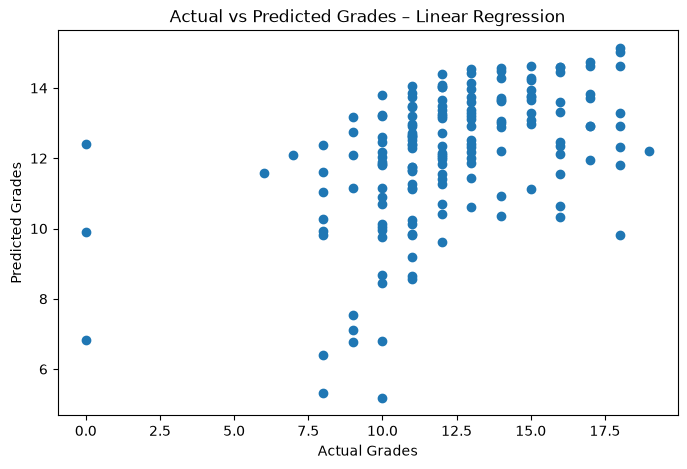

In [296]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test_25, y_pred_25)

plt.xlabel('Actual Grades')
plt.ylabel('Predicted Grades')
plt.title('Actual vs Predicted Grades – Linear Regression')

plt.show()

### Interpretation of Actual vs Predicted Grades – Linear Regression

The scatter plot compares the actual final grades with the grades predicted by Linear Regression.
The actual grades range from 0 to almost 20, while the predicted grades are mainly concentrated between approximately 6 and 15.
This shows that the model has difficulty predicting very low and very high grades. Most predictions are closer to the middle values.
Overall, the graph shows that Linear Regression has limited predictive performance when estimating students' final grades.

In [298]:
y_pred_rf_25 = rf_best_model.predict(X_test_25)

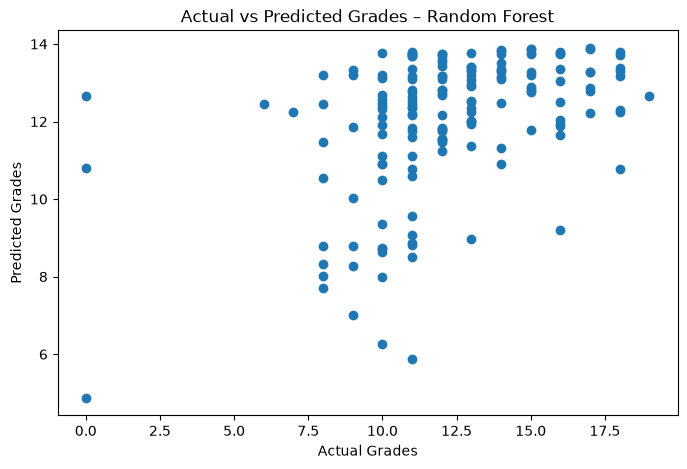

In [299]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test_25, y_pred_rf_25)
plt.xlabel('Actual Grades')
plt.ylabel('Predicted Grades')
plt.title('Actual vs Predicted Grades – Random Forest')
plt.show()

### Interpretation of Actual vs Predicted Grades – Random Forest

The scatter plot compares the actual final grades with the grades predicted by the tuned Random Forest model.
The horizontal axis represents the actual grades, while the vertical axis represents the predicted grades.
The points show how close the model's predictions are to the students' actual grades. A better-performing model would have predictions closer to the actual values. This graph helps us visually evaluate the Random Forest model and compare its predictions with those from Linear Regression.
The visual results should be considered together with the R², MAE and MSE metrics to evaluate the model's performance.

In [300]:
importances = rf_best_model.feature_importances_

In [301]:
feature_names = X_train_25.columns

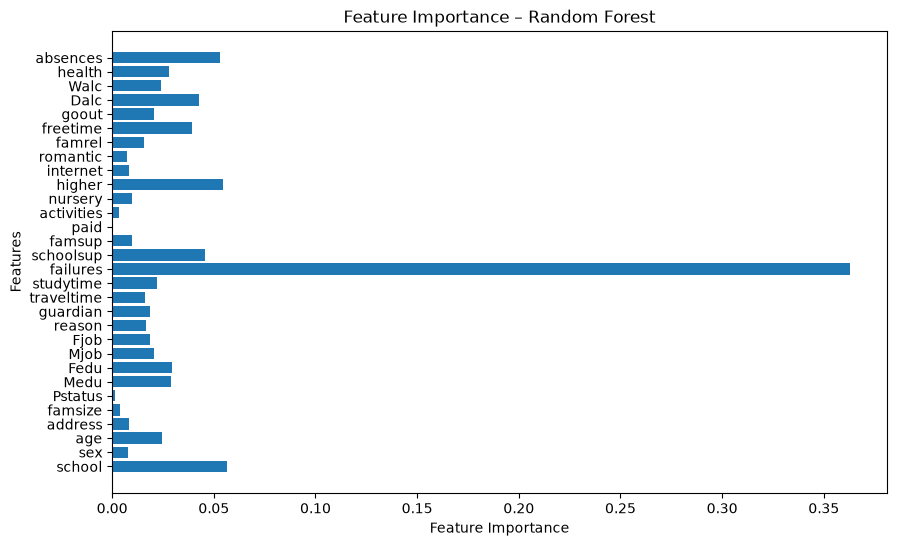

In [302]:
plt.figure(figsize=(10, 6))
plt.barh(feature_names, importances)
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Feature Importance – Random Forest')
plt.show()

### Interpretation of Feature Importance – Random Forest

The feature importance graph shows how much each variable contributes to the predictions made by the tuned Random Forest model.
The variable failures has the highest importance, with a value close to 0.35. This indicates that previous class failures are the most influential feature used by this model to predict students' final grades. Other variables, such as school, absences and  higher, show moderate importance.
Many of the remaining variables have very low importance in comparison.

Overall, the results suggest that previous academic failures are particularly useful for predicting final academic performance in Portuguese. However, feature importance indicates the model's predictive reliance on a variable, not a causal relationship.

### Comparison of the Three Train-Test Splits

The three train-test splits produced different results for the Machine Learning models.

**Linear Regression** achieved relatively consistent results across the three splits. Its R² scores were 0.1722 with a 5% test set, 0.2167 with a 15% test set and 0.2160 with a 25% test set. The best R² result was obtained with the 15% test set.

**Decision Tree Regressor** produced negative R² scores in all three splits: -0.0370, -0.6535 and -0.4923, respectively. These results indicate that the model performed poorly compared with a simple mean-based prediction.

**Random Forest Regressor** achieved positive R² scores across all three splits: 0.0839, 0.1310 and 0.1771. Its best result was obtained with the 25% test set.

Overall, Linear Regression performed best with the 5% and 15% test sets, while Random Forest achieved its best result with the 25% test set. The results show that the choice of train-test split can affect model performance.

### Cross-Validation Results

Cross-validation was performed using 10 folds on the training data from the 75/25 split.

Linear Regression achieved an average R² score of 0.2491. This indicates that the model explained approximately 24.91% of the variation in the final grades across the cross-validation results.

Decision Tree Regressor achieved an average R² score of -0.5616. This negative result indicates poor predictive performance and suggests that the model did not generalise well to different subsets of the training data.

Random Forest Regressor achieved the highest average R² score of 0.2693, slightly higher than Linear Regression.

Overall, Random Forest showed the best average cross-validation performance, although the difference compared with Linear Regression was small. Decision Tree performed considerably worse than both models.

### Hyperparameter Tuning Results

Hyperparameter tuning was performed using GridSearchCV with 10-fold cross-validation.

For the Decision Tree model, the best parameters were max_depth=3 and min_samples_split=10. Its average cross-validation R² score improved from -0.5616 before tuning to 0.2245 after tuning.

On the 25% test set, its R² score improved from -0.4923 to 0.1220. Its MAE decreased from 2.9080 to 2.1579, while its MSE decreased from 15.0429 to 8.8509.

For the Random Forest model, the best parameters were max_depth=5 and n_estimators=50. Its average cross-validation R² score increased slightly from 0.2693 to 0.2784.

However, its test results did not improve after tuning. The R² score decreased slightly from 0.1771 to 0.1762, while MAE increased from 2.1075 to 2.1444 and MSE increased from 8.2950 to 8.3047.

Overall, hyperparameter tuning significantly improved the Decision Tree model. However, it produced only a small improvement in Random Forest's cross-validation score and did not improve its test performance.

### Most Important Predictive Features

The Random Forest feature importance analysis identified failures as the most important feature, with an importance value close to 0.35.

Other features, including school, absences and higher, also showed some predictive importance.

This suggests that previous academic failures, school-related information and student absences are useful features for predicting final academic performance in Portuguese.

However, feature importance does not demonstrate a causal relationship. It only indicates how much the trained Random Forest model relied on each feature when making predictions.

The results also show that demographic and social variables contributed less to the model's predictions compared with the most important features.

### Project Limitations

This project has some limitations that should be considered when interpreting the results.

Firstly, the dataset contains 649 students from the Portuguese subject only. Therefore, the findings may not represent students from other subjects or educational settings.
Secondly, the variables G1 and G2 were excluded from the prediction models. This decision was made to investigate whether academic, demographic and social factors could predict the final grade without using previous period grades. However, excluding these variables may reduce the predictive performance of the models.
Thirdly, LabelEncoder was used to convert categorical variables into numerical values. This method assigns numerical labels to categories, which may introduce an artificial order between categories that do not have a natural ranking. This could affect how some models interpret the data, particularly Linear Regression.

Finally, the models achieved relatively low R² scores, indicating that a considerable proportion of the variation in final grades was not explained by the selected features.

### Overall Conclusion

This project investigated how academic, demographic and social factors can be used to predict students' final academic performance in Portuguese using Machine Learning.
Three regression models were evaluated: Linear Regression, Decision Tree Regressor and Random Forest Regressor. The models were tested using three different train-test splits: 95/5, 85/15 and 75/25. The results showed that Linear Regression achieved the best test performance in the 95/5 and 85/15 splits. In the 75/25 split, Linear Regression also achieved the highest test R² score of 0.2160, compared with 0.1771 for the original Random Forest model and -0.4923 for the original Decision Tree model.
Cross-validation produced a slightly different result. Random Forest achieved the highest average R² score of 0.2693, followed by Linear Regression with 0.2491. Decision Tree performed poorly, with an average R² score of -0.5616. Hyperparameter tuning significantly improved the Decision Tree model. However, tuning did not improve the Random Forest model's performance on the 25% test set. The feature importance analysis identified failures as the most influential predictor, followed by variables such as school, absences and higher.

Overall, the findings suggest that previous academic failures and student-related factors provide useful information for predicting final grades. However, the relatively low R² scores indicate that the models have limited predictive ability.
Linear Regression achieved the strongest overall test results, while Random Forest obtained the highest average cross-validation score. Therefore, neither model demonstrated a clear advantage across every evaluation method.